# 3. Base model: the normal image process

This is the **untrained** Qwen2-VL-2B, fed the way it normally takes images: the screenshot is shrunk to fit 720x1280 and it answers in free text.

It was never taught what a UI defect is, so expect vague or wrong answers. This is the starting line that every adapter has to beat. **Green box** = where the defect really is. **Red box** = where the model says it is (approximate).

In [1]:
import sys, time
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import HTML, display
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'demo_inputs').exists())
sys.path.insert(0, str(C3.parent))
import vision_oracle.services.oracle_service   # must be imported first (path guard for the local package)
from local_vision_oracle.engine import load_inference_contract, contract_messages
from local_vision_oracle import notebook_runs as nr
MODELS = C3 / 'models'
DEMO = C3 / 'demo_inputs'

def banner(title, sub='', color='#1e3a8a'):
    display(HTML(f'<div style="background:{color};color:white;padding:14px 18px;border-radius:8px;margin:14px 0 6px">'
                 f'<div style="font-size:20px;font-weight:700">{title}</div><div style="opacity:.85;margin-top:2px">{sub}</div></div>'))

def show(ax, image, answer=None, gold=None, title='', ok=None):
    ax.imshow(image); ax.axis('off'); W, H = image.size
    g = nr.box_to_pixels(gold, W, H)
    if g: ax.add_patch(Rectangle(g[:2], g[2], g[3], fill=False, ec='lime', lw=3))
    b = nr.box_to_pixels((answer or {}).get('box'), W, H)
    if b and (answer or {}).get('type') not in (None, 'none'): ax.add_patch(Rectangle(b[:2], b[2], b[3], fill=False, ec='red', lw=3))
    ax.set_title(title, fontsize=9, color={True: 'green', False: 'red', None: 'black'}[ok])

def one_line(name, true_type, a):
    ok = a['type'] == true_type
    print(f"{name:<28} said: {a['type']:<18} {'CORRECT' if ok else 'wrong':<8} {a['seconds']:>5.1f} s")
    return ok

NAMES = list(nr.SCREENS)
banner('Loading the base model', 'No adapter. About 20 seconds', '#64748b')
backend = nr.load_backend(MODELS, None)
backend.inference_contract = None            # the default path
PROMPT = load_inference_contract(str(MODELS / 'c3_v3_vision_1ep'))['user_prompt']   # same question the adapters are asked
messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT}]}]
nr.run_once(backend, Image.open(DEMO / NAMES[0]).convert('RGB'), messages)   # warm-up, not shown
answers = {n: nr.run_once(backend, Image.open(DEMO / n).convert('RGB'), messages) for n in NAMES}
nr.free_backend(backend)
print('done, model released')

C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:00<11:01,  1.10it/s]

Loading weights:   0%|          | 3/729 [00:01<03:48,  3.18it/s]

Loading weights:   1%|          | 5/729 [00:01<02:16,  5.32it/s]

...

Loading weights:  93%|█████████▎| 678/729 [00:08<00:00, 164.46it/s]

Loading weights:  95%|█████████▌| 695/729 [00:08<00:00, 157.94it/s]

Loading weights:  98%|█████████▊| 716/729 [00:08<00:00, 164.96it/s]

Loading weights: 100%|██████████| 729/729 [00:08<00:00, 84.94it/s] 

done, model released


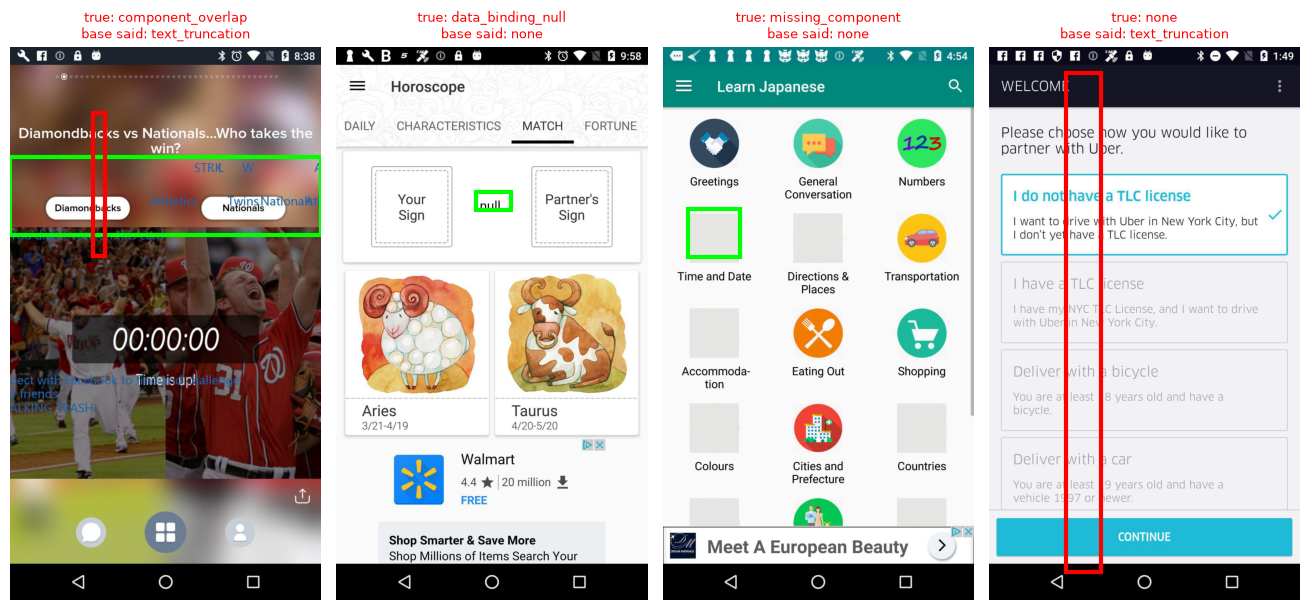

01_overlap_team_names.jpg    said: text_truncation    wrong      4.5 s
03_null_text.jpg             said: none               wrong      4.2 s
04_missing_icons.jpg         said: none               wrong      4.1 s
07_clean_owleye.jpg          said: text_truncation    wrong      4.4 s

Base model named the right type on 0 of 4 screens.


In [2]:
banner('What the base model said', 'Same four screens every adapter is shown later', '#64748b')
fig, ax = plt.subplots(1, len(NAMES), figsize=(3.3 * len(NAMES), 6.2))
hits = 0
for a, n in zip(ax, NAMES):
    true_type, gold = nr.SCREENS[n]; ans = answers[n]; ok = ans['type'] == true_type; hits += ok
    show(a, Image.open(DEMO / n).convert('RGB'), ans, gold, f"true: {true_type}\nbase said: {ans['type']}", ok)
plt.tight_layout(); plt.show()
for n in NAMES: one_line(n, nr.SCREENS[n][0], answers[n])
print(f'\nBase model named the right type on {hits} of {len(NAMES)} screens.')

## What to conclude
The base model does not know this task: it mostly says nothing is wrong or names the wrong problem. Notebook 4 runs the same screens through each adapter.